# Análisis estadístico: costo del seguro médico

**Equipo:** Juan Manuel Machado Acosta · Mateo Corrales Vinasco

**Pregunta principal:** ¿Qué factores explican el costo del seguro médico (`charges`) y cuánto aumenta para una persona fumadora?

**Fuente de los datos:** https://www.kaggle.com/datasets/mirichoi0218/insurance. 
**Idea del problema (según el enunciado del curso):** costo del seguro médico según edad, IMC y hábito de fumar.

**Librerías:** pandas, numpy, matplotlib, seaborn, scipy, statsmodels.

> Notebook organizado siguiendo las secciones de la Fase 2 del documento de trabajo final:
> 1. Preparación de datos · 2. Estadística descriptiva · 3. Estadística probabilística ·
> 4. Estadística inferencial · 5. Regresión lineal · 6. Conclusiones.


In [1]:
# Configuración general y estilo profesional de los gráficos
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Estilo consistente y profesional
sns.set_theme(style="whitegrid", context="notebook", palette="deep", font_scale=1.05)
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 150,
    "axes.titlesize": 13,
    "axes.titleweight": "bold",
    "axes.labelsize": 11,
    "axes.edgecolor": "#444444",
    "grid.alpha": 0.25,
    "font.family": "DejaVu Sans",
})

def style_axes(ax, title, xlabel, ylabel):
    ax.set_title(title, pad=12)
    ax.set_xlabel(xlabel)
    ax.set_ylabel(ylabel)
    ax.grid(True, alpha=0.25)

print("Librerías cargadas correctamente.")


Librerías cargadas correctamente.


## Fase 1 · Problema y base de datos

El problema es realista y se responde con datos públicos. La base `insurance.csv` contiene **1.338 registros** y **7 variables**:

| Variable | Tipo | Descripción |
|---|---|---|
| `age` | cuantitativa discreta | Edad del beneficiario (años) |
| `sex` | categórica | Sexo (`male`/`female`) |
| `bmi` | cuantitativa continua | Índice de masa corporal (kg/m²) |
| `children` | cuantitativa discreta (conteo) | Número de hijos/dependientes cubiertos |
| `smoker` | categórica binaria | Fumador (`yes`/`no`) |
| `region` | categórica | Región de residencia en EE. UU. |
| `charges` | cuantitativa continua | Costo del seguro médico (USD) — **variable respuesta** |

Cumple los requisitos mínimos del curso: más de 300 observaciones, al menos 3 cuantitativas continuas (`bmi`, `charges` y `age`), 1 de conteo (`children`) y 2 categóricas (`sex`, `smoker`, `region`), además de un grupo de comparación (`smoker`).


## 1. Preparación de datos

Se describen los tipos de variable, el tratamiento de faltantes, duplicados y atípicos, y se crean variables derivadas útiles para el análisis.


In [2]:
df = pd.read_csv("./datos/insurance.csv")
df = df.copy()

# Estandarización de texto
for col in ["sex", "smoker", "region"]:
    df[col] = df[col].astype(str).str.strip().str.lower()

# Variable derivada: indicador numérico de fumador (útil para correlaciones)
df["smoker_num"] = df["smoker"].map({"yes": 1, "no": 0})

print("Dimensiones:", df.shape)
df.head()


Dimensiones: (1338, 8)


,age,sex,bmi,children,smoker,region,charges,smoker_num
0,19,female,27.900,0,yes,southwest,16884.92400,1
1,18,male,33.770,1,no,southeast,1725.55230,0
2,28,male,33.000,3,no,southeast,4449.46200,0
3,33,male,22.705,0,no,northwest,21984.47061,0
4,32,male,28.880,0,no,northwest,3866.85520,0


In [3]:
print("Tipos de datos:")
print(df.dtypes)
print("\nValores faltantes por variable:")
print(df.isna().sum())
print("\nFilas duplicadas:", df.duplicated().sum())


Tipos de datos:
age             int64
sex               str
bmi           float64
children        int64
smoker            str
region            str
charges       float64
smoker_num      int64
dtype: object

Valores faltantes por variable:
age           0
sex           0
bmi           0
children      0
smoker        0
region        0
charges       0
smoker_num    0
dtype: int64

Filas duplicadas: 1


In [4]:
# Eliminación de duplicados (justificada: registro exactamente repetido)
n0 = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Filas antes: {n0}  |  después de quitar duplicados: {len(df)}  |  eliminadas: {n0-len(df)}")


Filas antes: 1338  |  después de quitar duplicados: 1337  |  eliminadas: 1


In [5]:
# Detección de atípicos por IQR (solo para diagnóstico; no se eliminan automáticamente)
def iqr_bounds(s):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1 - 1.5*iqr, q3 + 1.5*iqr

for col in ["age", "bmi", "children", "charges"]:
    lo, hi = iqr_bounds(df[col])
    n_out = int(((df[col] < lo) | (df[col] > hi)).sum())
    print(f"{col:9s} | límites IQR: [{lo:9.2f}, {hi:9.2f}] | atípicos: {n_out}")


age       | límites IQR: [    -9.00,     87.00] | atípicos: 0
bmi       | límites IQR: [    13.67,     47.32] | atípicos: 9
children  | límites IQR: [    -3.00,      5.00] | atípicos: 0
charges   | límites IQR: [-13120.72,  34524.78] | atípicos: 139


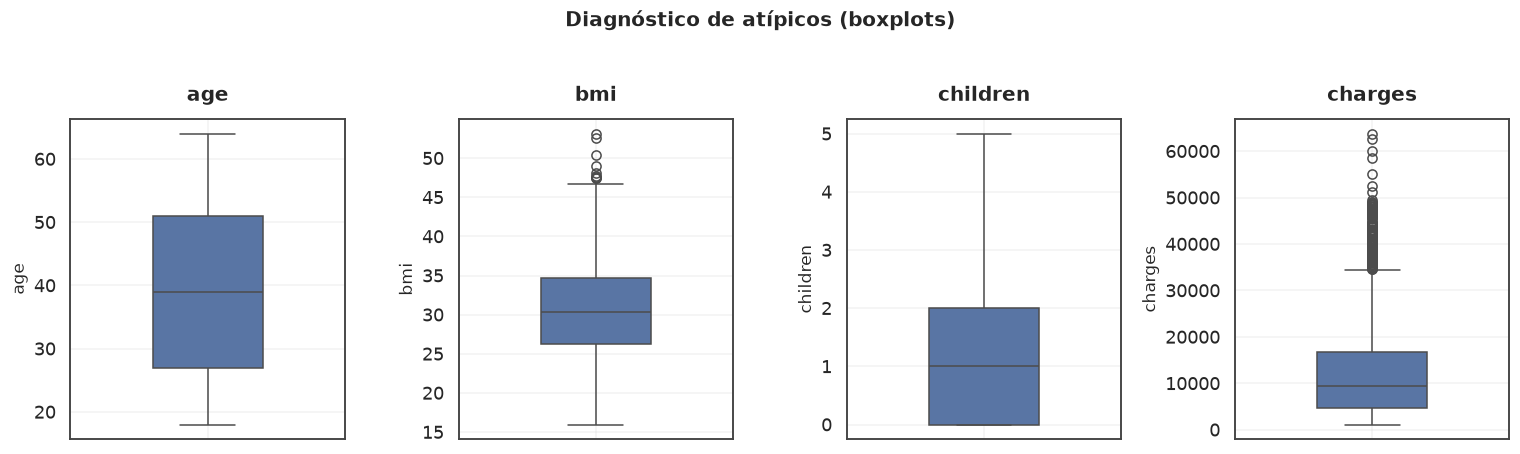

In [6]:
# Boxplots de diagnóstico por variable numérica
num_cols = ["age", "bmi", "children", "charges"]
fig, axes = plt.subplots(1, len(num_cols), figsize=(14, 4))
for ax, col in zip(axes, num_cols):
    sns.boxplot(y=df[col], ax=ax, color="#4C72B0", width=0.4)
    style_axes(ax, col, "", col)
plt.suptitle("Diagnóstico de atípicos (boxplots)", y=1.03, fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()


**Interpretación de la preparación.** No hay valores faltantes. Se encontró un registro exactamente duplicado y se eliminó. Los atípicos de `charges` corresponden principalmente a fumadores y a personas con IMC alto, es decir, son casos reales del fenómeno y no errores de captura; por eso se **retienen**. Los atípicos de `bmi` (IMC > 45) son plausibles clínicamente. No se imputa ninguna variable porque no hay faltantes.


## 2. Estadística descriptiva

Tabla de resumen, tablas de frecuencia y de contingencia, matriz de correlación y gráficos de distintos tipos.


In [7]:
resumen = df[["age", "bmi", "children", "charges"]].agg(
    ["count", "mean", "median", "std", "min", "max"]
).T
resumen["q1"] = df[["age", "bmi", "children", "charges"]].quantile(0.25)
resumen["q3"] = df[["age", "bmi", "children", "charges"]].quantile(0.75)
resumen["skew"] = df[["age", "bmi", "children", "charges"]].skew()
resumen = resumen.round(2)
resumen


,count,mean,median,std,min,max,q1,q3,skew
age,1337.0,39.22,39.00,14.04,18.00,64.00,27.00,51.00,0.05
bmi,1337.0,30.66,30.40,6.10,15.96,53.13,26.29,34.70,0.28
children,1337.0,1.10,1.00,1.21,0.00,5.00,0.00,2.00,0.94
charges,1337.0,13279.12,9386.16,12110.36,1121.87,63770.43,4746.34,16657.72,1.52


In [8]:
print("Frecuencias - sexo:")
print(df["sex"].value_counts())
print("\nFrecuencias - fumador:")
print(df["smoker"].value_counts())
print("\nFrecuencias - región:")
print(df["region"].value_counts())
print("\nFrecuencias - hijos (children):")
print(df["children"].value_counts().sort_index())


Frecuencias - sexo:
sex
male      675
female    662
Name: count, dtype: int64

Frecuencias - fumador:
smoker
no     1063
yes     274
Name: count, dtype: int64

Frecuencias - región:
region
southeast    364
southwest    325
northwest    324
northeast    324
Name: count, dtype: int64

Frecuencias - hijos (children):
children
0    573
1    324
2    240
3    157
4     25
5     18
Name: count, dtype: int64


In [9]:
print("Tabla de contingencia: sexo × fumador")
tab_sexo_fum = pd.crosstab(df["sex"], df["smoker"], margins=True)
tab_sexo_fum


Tabla de contingencia: sexo × fumador


smoker,no,yes,All
sex,,,
female,547,115,662
male,516,159,675
All,1063,274,1337


In [10]:
print("Tabla de contingencia: región × fumador")
tab_reg_fum = pd.crosstab(df["region"], df["smoker"], margins=True)
tab_reg_fum


Tabla de contingencia: región × fumador


smoker,no,yes,All
region,,,
northeast,257,67,324
northwest,266,58,324
southeast,273,91,364
southwest,267,58,325
All,1063,274,1337


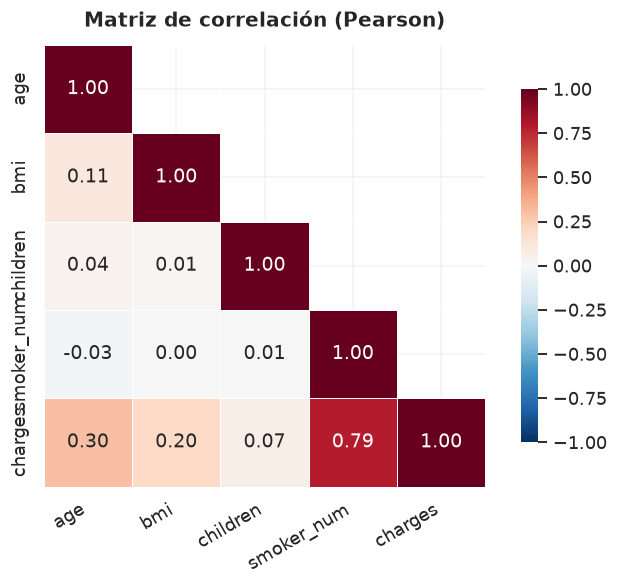

In [11]:
# Matriz de correlación (Pearson) entre variables numéricas
num_for_corr = ["age", "bmi", "children", "smoker_num", "charges"]
corr = df[num_for_corr].corr(method="pearson")

fig, ax = plt.subplots(figsize=(7, 5.5))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
            vmin=-1, vmax=1, square=True, linewidths=0.6, cbar_kws={"shrink": 0.8}, ax=ax)
style_axes(ax, "Matriz de correlación (Pearson)", "", "")
ax.set_xticklabels(ax.get_xticklabels(), rotation=30, ha="right")
plt.tight_layout()
plt.show()


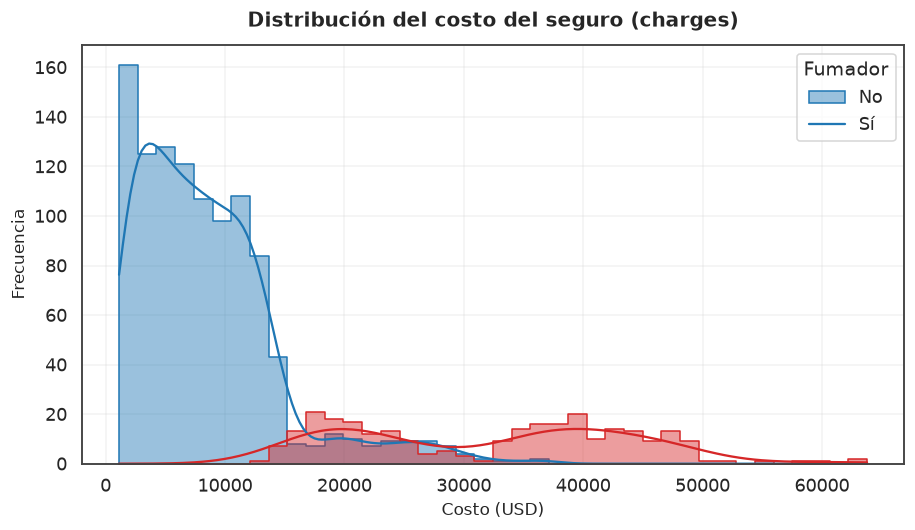

In [12]:
# 1) Histograma de charges con KDE, por hábito de fumar
fig, ax = plt.subplots(figsize=(8.5, 5))
sns.histplot(data=df, x="charges", hue="smoker", kde=True, bins=40, ax=ax,
             palette={"yes": "#d62728", "no": "#1f77b4"}, alpha=0.45, element="step")
style_axes(ax, "Distribución del costo del seguro (charges)", "Costo (USD)", "Frecuencia")
ax.legend(title="Fumador", labels=["No", "Sí"])
plt.tight_layout()
plt.show()


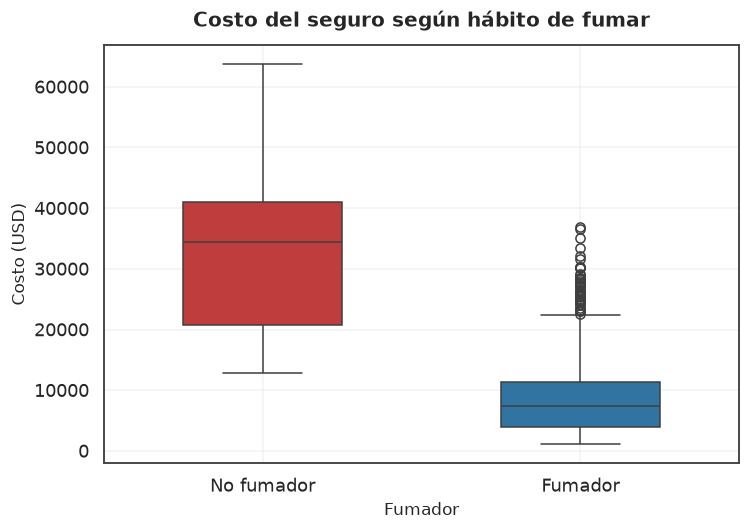

In [13]:
# 2) Boxplot de charges por fumador
fig, ax = plt.subplots(figsize=(7, 5))
sns.boxplot(data=df, x="smoker", y="charges", hue="smoker", palette={"yes": "#d62728", "no": "#1f77b4"},
            ax=ax, legend=False, width=0.5)
ax.set_xticklabels(["No fumador", "Fumador"])
style_axes(ax, "Costo del seguro según hábito de fumar", "Fumador", "Costo (USD)")
plt.tight_layout()
plt.show()


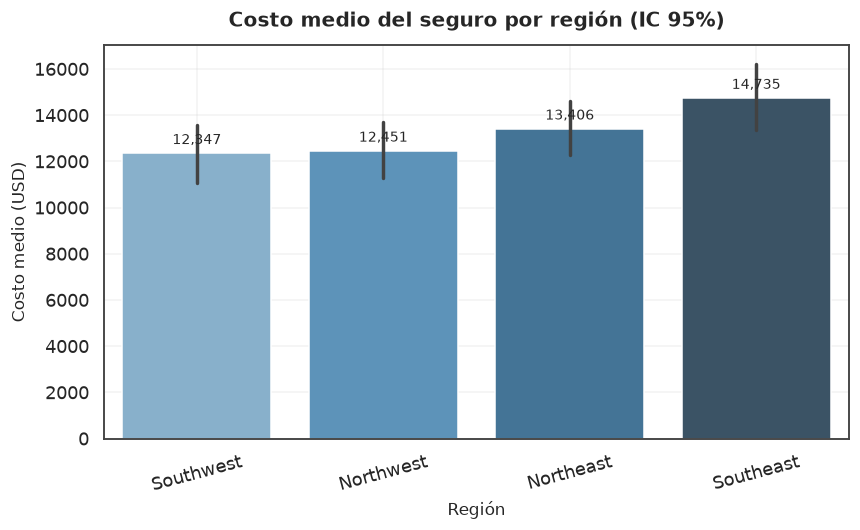

In [14]:
# 3) Barras: costo medio por región (con IC 95%)
order_reg = df.groupby("region")["charges"].mean().sort_values().index
fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=df, x="region", y="charges", order=order_reg, errorbar=("ci", 95),
            palette="Blues_d", ax=ax)
for p in ax.patches:
    ax.annotate(f"{p.get_height():,.0f}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=9, xytext=(0, 4), textcoords="offset points")
style_axes(ax, "Costo medio del seguro por región (IC 95%)", "Región", "Costo medio (USD)")
ax.set_xticklabels([r.capitalize() for r in order_reg], rotation=15)
plt.tight_layout()
plt.show()


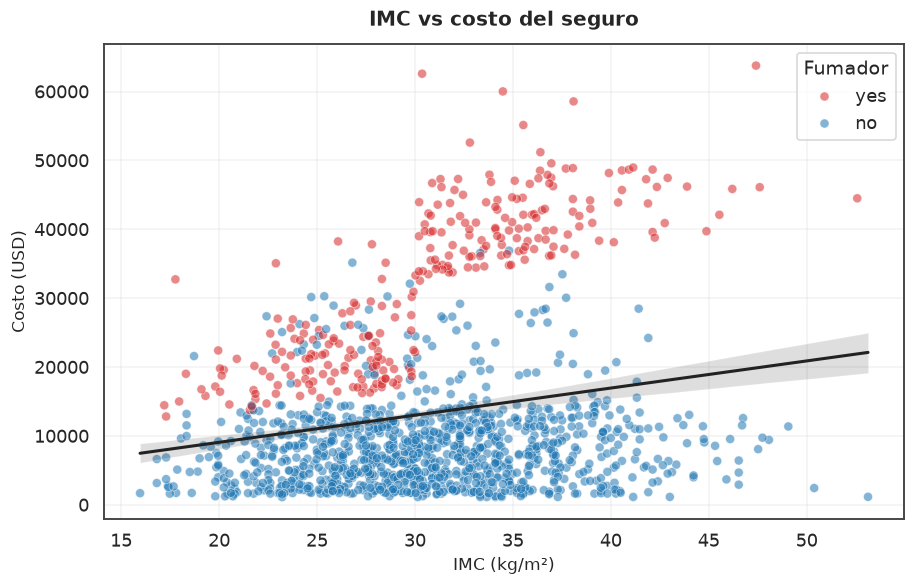

In [15]:
# 4) Dispersión: IMC vs charges, coloreado por fumador + recta de regresión
fig, ax = plt.subplots(figsize=(8.5, 5.5))
sns.scatterplot(data=df, x="bmi", y="charges", hue="smoker", alpha=0.55, ax=ax,
                palette={"yes": "#d62728", "no": "#1f77b4"}, s=35)
sns.regplot(data=df, x="bmi", y="charges", scatter=False, color="#222222", ax=ax,
            line_kws={"linewidth": 2, "label": "Tendencia global"})
style_axes(ax, "IMC vs costo del seguro", "IMC (kg/m²)", "Costo (USD)")
ax.legend(title="Fumador")
plt.tight_layout()
plt.show()


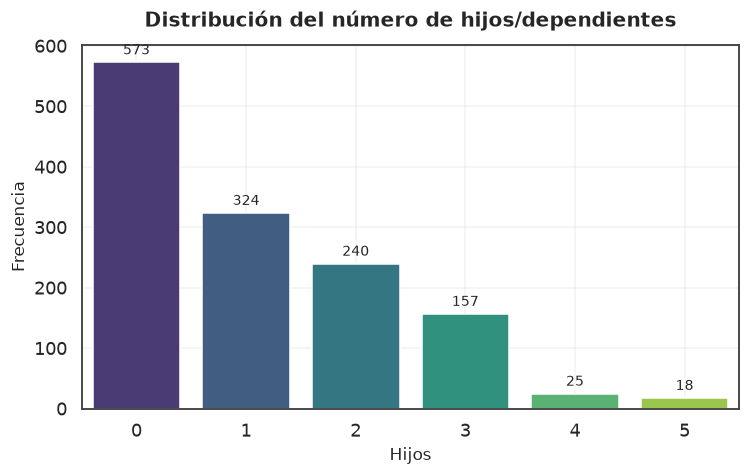

In [16]:
# 5) Conteo de hijos (barras)
fig, ax = plt.subplots(figsize=(7, 4.5))
order_ch = sorted(df["children"].unique())
sns.countplot(data=df, x="children", order=order_ch, palette="viridis", ax=ax)
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width()/2, p.get_height()),
                ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")
style_axes(ax, "Distribución del número de hijos/dependientes", "Hijos", "Frecuencia")
plt.tight_layout()
plt.show()


**Interpretación descriptiva.** El costo (`charges`) es fuertemente asimétrico a la derecha: la mediana (~9.4 mil USD) es mucho menor que la media (~13.3 mil USD) por la cola de costos altos. Los fumadores presentan cargos muy superiores (boxplot). El IMC y la edad tienen correlación positiva con `charges`, pero el factor más marcado es `smoker`. Las regiones muestran diferencias moderadas. `children` se concentra en 0–2 hijos.


## 3. Estadística probabilística

Se ajustan distribuciones (una continua y una discreta), se comparan con histograma/QQ-plot y se calculan probabilidades de interés comparándolas con la frecuencia observada.


Ajuste Normal a BMI: μ = 30.663, σ = 6.098
Kolmogorov-Smirnov: D = 0.0264, p = 0.3031


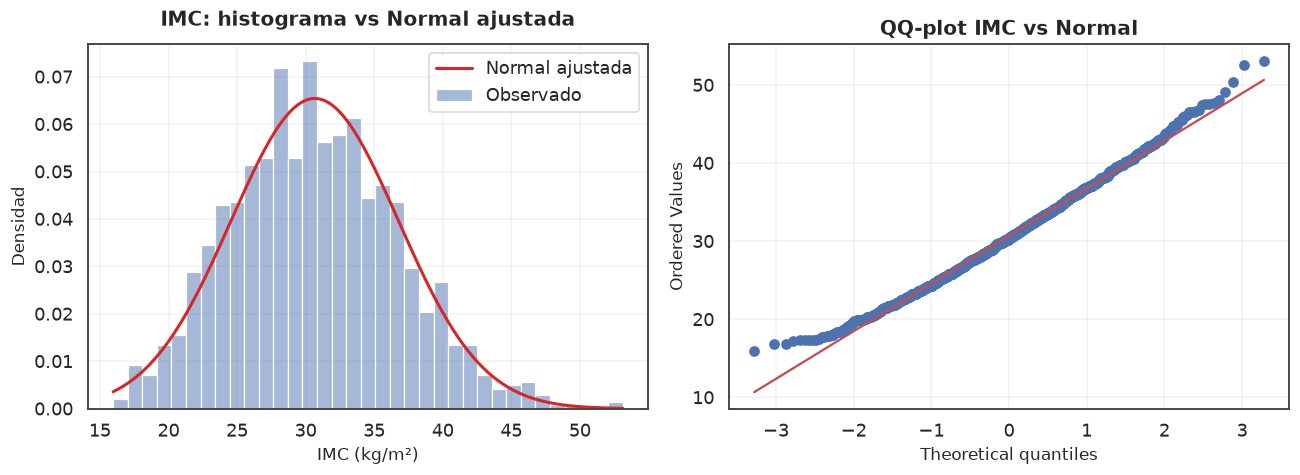

In [17]:
# --- Continua 1: IMC (bmi) ~ Normal ---
mu, sigma = stats.norm.fit(df["bmi"])
print(f"Ajuste Normal a BMI: μ = {mu:.3f}, σ = {sigma:.3f}")

ks_stat, ks_p = stats.kstest(df["bmi"], lambda x: stats.norm.cdf(x, loc=mu, scale=sigma))
print(f"Kolmogorov-Smirnov: D = {ks_stat:.4f}, p = {ks_p:.4g}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
# Histograma + pdf
sns.histplot(df["bmi"], bins=35, stat="density", color="#4C72B0", alpha=0.5, ax=axes[0], label="Observado")
x = np.linspace(df["bmi"].min(), df["bmi"].max(), 200)
axes[0].plot(x, stats.norm.pdf(x, mu, sigma), color="#d62728", lw=2, label="Normal ajustada")
style_axes(axes[0], "IMC: histograma vs Normal ajustada", "IMC (kg/m²)", "Densidad")
axes[0].legend()
# QQ-plot
stats.probplot(df["bmi"], dist="norm", plot=axes[1])
axes[1].set_title("QQ-plot IMC vs Normal", fontweight="bold")
axes[1].grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


Ajuste Gamma a charges: shape (a) = 1.412, loc = 0.000, scale = 9401.480


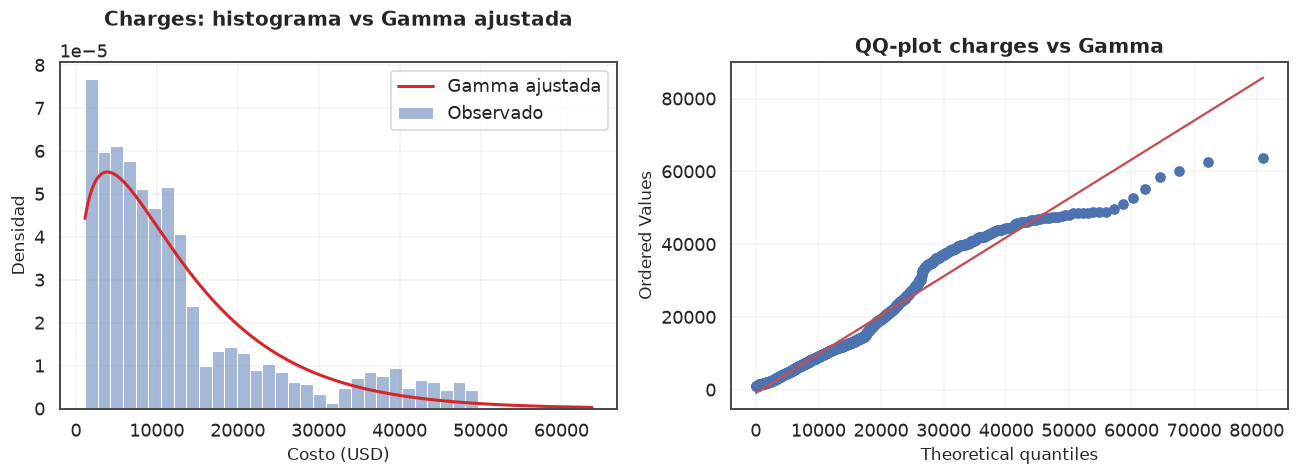

In [18]:
# --- Continua 2: charges ~ Gamma (floc=0) ---
a, loc, scale = stats.gamma.fit(df["charges"], floc=0)
print(f"Ajuste Gamma a charges: shape (a) = {a:.3f}, loc = {loc:.3f}, scale = {scale:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.histplot(df["charges"], bins=40, stat="density", color="#4C72B0", alpha=0.5, ax=axes[0], label="Observado")
x = np.linspace(df["charges"].min(), df["charges"].max(), 300)
axes[0].plot(x, stats.gamma.pdf(x, a, loc=loc, scale=scale), color="#d62728", lw=2, label="Gamma ajustada")
style_axes(axes[0], "Charges: histograma vs Gamma ajustada", "Costo (USD)", "Densidad")
axes[0].legend()
stats.probplot(df["charges"], dist="gamma", sparams=(a, loc, scale), plot=axes[1])
axes[1].set_title("QQ-plot charges vs Gamma", fontweight="bold")
axes[1].grid(True, alpha=0.25)
plt.tight_layout()
plt.show()


Media de children (λ estimado) = 1.096


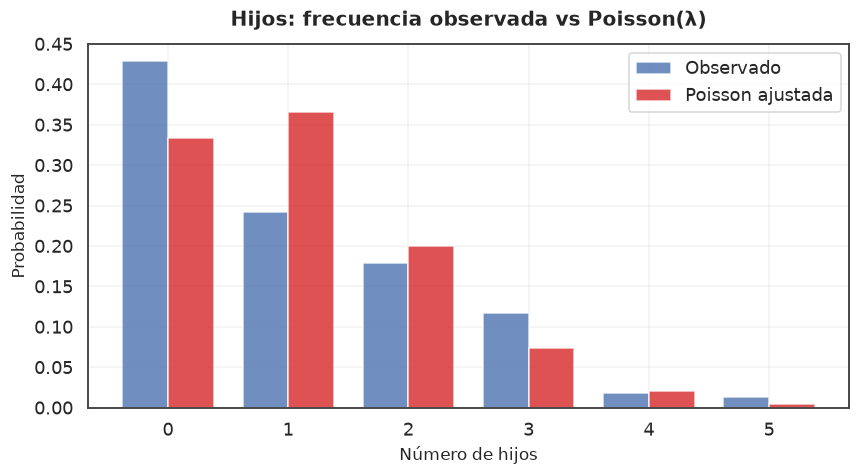

In [19]:
# --- Discreta: children ~ Poisson ---
lam = df["children"].mean()
print(f"Media de children (λ estimado) = {lam:.3f}")

x_vals = np.arange(0, df["children"].max() + 1)
pmf_poisson = stats.poisson.pmf(x_vals, lam)
obs_freq = df["children"].value_counts(normalize=True).reindex(x_vals, fill_value=0)

fig, ax = plt.subplots(figsize=(8, 4.5))
width = 0.38
ax.bar(x_vals - width/2, obs_freq.values, width, label="Observado", color="#4C72B0", alpha=0.8)
ax.bar(x_vals + width/2, pmf_poisson, width, label="Poisson ajustada", color="#d62728", alpha=0.8)
style_axes(ax, "Hijos: frecuencia observada vs Poisson(λ)", "Número de hijos", "Probabilidad")
ax.set_xticks(x_vals)
ax.legend()
plt.tight_layout()
plt.show()


In [20]:
# --- Bernoulli para fumador ---
p_smoke = df["smoker_num"].mean()
print(f"Proporción de fumadores p = {p_smoke:.4f}  (Bernoulli)")

# Probabilidades de interés: modelo vs frecuencia observada
print("\nProbabilidades de interés (modelo vs observado):")
print("-" * 60)

# 1) P(charges > 20000) con Gamma
p1_model = stats.gamma.sf(20000, a, loc=loc, scale=scale)
p1_obs   = (df["charges"] > 20000).mean()
print(f"P(charges > 20.000):  Gamma = {p1_model:.4f}  |  observado = {p1_obs:.4f}")

# 2) P(bmi > 30) con Normal
p2_model = stats.norm.sf(30, mu, sigma)
p2_obs   = (df["bmi"] > 30).mean()
print(f"P(bmi > 30):          Normal = {p2_model:.4f}  |  observado = {p2_obs:.4f}")

# 3) P(children >= 3) con Poisson
p3_model = stats.poisson.sf(2, lam)  # P(X >= 3) = 1 - P(X<=2)
p3_obs   = (df["children"] >= 3).mean()
print(f"P(children >= 3):     Poisson = {p3_model:.4f}  |  observado = {p3_obs:.4f}")

# 4) P(fumador) Bernoulli
p4_model = p_smoke
p4_obs   = df["smoker"].eq("yes").mean()
print(f"P(fumador):           Bernoulli = {p4_model:.4f}  |  observado = {p4_obs:.4f}")


Proporción de fumadores p = 0.2049  (Bernoulli)

Probabilidades de interés (modelo vs observado):
------------------------------------------------------------
P(charges > 20.000):  Gamma = 0.2129  |  observado = 0.2042
P(bmi > 30):          Normal = 0.5433  |  observado = 0.5266
P(children >= 3):     Poisson = 0.0987  |  observado = 0.1496
P(fumador):           Bernoulli = 0.2049  |  observado = 0.2049


**Interpretación probabilística.** El IMC se aproxima razonablemente por una Normal (μ ≈ 30.7, σ ≈ 6.1), aunque con ligera asimetría. `charges` es mejor descrito por una Gamma (cola derecha pesada) que por una Normal. El número de hijos no sigue bien una Poisson (hay más ceros y menos valores altos de los esperados), lo que sugiere sobredispersión; aun así sirve como modelo base. Las probabilidades del modelo se acercan a las frecuencias observadas, con las mayores diferencias en la cola de `charges`, donde la mezcla de fumadores/no fumadores genera bimodalidad.


## 4. Estadística inferencial

Se construyen intervalos de confianza y se realizan pruebas de hipótesis. Para cada prueba se reportan H₀, H₁, supuestos, estadístico, valor p, decisión y tamaño del efecto.


In [21]:
# Intervalos de confianza
def t_ci(series, conf=0.95):
    n = len(series)
    mean = series.mean()
    se = series.std(ddof=1) / np.sqrt(n)
    tcrit = stats.t.ppf((1+conf)/2, df=n-1)
    return mean, mean - tcrit*se, mean + tcrit*se

m, lo, hi = t_ci(df["charges"])
print(f"IC 95% media de charges: {m:,.2f}  [{lo:,.2f}, {hi:,.2f}]")

m, lo, hi = t_ci(df["bmi"])
print(f"IC 95% media de BMI:     {m:.2f}  [{lo:.2f}, {hi:.2f}]")

# IC para proporción de fumadores (Wilson)
from statsmodels.stats.proportion import proportion_confint
ci_low, ci_high = proportion_confint(count=(df["smoker"]=="yes").sum(), nobs=len(df), alpha=0.05, method="wilson")
print(f"IC 95% proporción de fumadores: {p_smoke:.4f}  [{ci_low:.4f}, {ci_high:.4f}]")


IC 95% media de charges: 13,279.12  [12,629.39, 13,928.85]
IC 95% media de BMI:     30.66  [30.34, 30.99]
IC 95% proporción de fumadores: 0.2049  [0.1842, 0.2274]


### Prueba 1 · Una muestra (t de Student)

**H₀:** μ_BMI = 30 (el IMC medio poblacional es 30).  
**H₁:** μ_BMI ≠ 30.  
**Supuestos:** muestra aleatoria; n grande (CLT) para la media; se revisa normalidad aproximada.  
**Estadístico:** t de Student de una muestra.  
**Tamaño del efecto:** d de Cohen.


In [22]:
t_stat, p_val = stats.ttest_1samp(df["bmi"], 30)
d_cohen = (df["bmi"].mean() - 30) / df["bmi"].std(ddof=1)
print(f"t = {t_stat:.3f}, gl = {len(df)-1}, p = {p_val:.4g}")
print(f"Media muestral = {df['bmi'].mean():.3f}")
print(f"d de Cohen = {d_cohen:.3f}")
print("Decisión:", "Rechazar H0" if p_val < 0.05 else "No rechazar H0")


t = 3.977, gl = 1336, p = 7.365e-05
Media muestral = 30.663
d de Cohen = 0.109
Decisión: Rechazar H0


**Interpretación.** El IMC medio muestral (~30.66) es estadísticamente mayor que 30 (p < 0.05), pero el tamaño del efecto es pequeño (d ≈ 0.11), por lo que la diferencia es real pero de poca magnitud práctica.


### Prueba 2 · Dos grupos independientes (t de Welch)

**H₀:** μ_charges(fumador) = μ_charges(no fumador).  
**H₁:** μ_charges(fumador) ≠ μ_charges(no fumador).  
**Supuestos:** independencia de grupos; no se asume igualdad de varianzas (Welch).  
**Estadístico:** t de Welch.  
**Tamaño del efecto:** d de Cohen (varianzas agrupadas).


In [23]:
g_yes = df.loc[df["smoker"]=="yes", "charges"]
g_no  = df.loc[df["smoker"]=="no",  "charges"]

t_stat, p_val = stats.ttest_ind(g_yes, g_no, equal_var=False)
# Cohen's d con varianza agrupada
pooled_sd = np.sqrt(((len(g_yes)-1)*g_yes.var(ddof=1) + (len(g_no)-1)*g_no.var(ddof=1)) / (len(g_yes)+len(g_no)-2))
d_cohen = (g_yes.mean() - g_no.mean()) / pooled_sd
print(f"No fumadores: n={len(g_no)}, media={g_no.mean():,.2f}, DE={g_no.std(ddof=1):,.2f}")
print(f"Fumadores:    n={len(g_yes)}, media={g_yes.mean():,.2f}, DE={g_yes.std(ddof=1):,.2f}")
print(f"Welch t = {t_stat:.3f}, p = {p_val:.4g}")
print(f"d de Cohen = {d_cohen:.3f}")
print("Decisión:", "Rechazar H0" if p_val < 0.05 else "No rechazar H0")


No fumadores: n=1063, media=8,440.66, DE=5,992.97
Fumadores:    n=274, media=32,050.23, DE=11,541.55
Welch t = 32.742, p = 6.262e-103
d de Cohen = 3.160
Decisión: Rechazar H0


**Interpretación.** Los fumadores pagan significativamente más (diferencia ≈ 23.6 mil USD). El valor p es extremadamente pequeño y el tamaño del efecto es muy grande (d > 2), por lo que el hábito de fumar es el predictor más fuerte del costo.


### Prueba 3 · Independencia (χ² de Pearson)

**H₀:** `sex` y `smoker` son independientes.  
**H₁:** `sex` y `smoker` están asociados.  
**Supuestos:** frecuencias esperadas ≥ 5 en todas las celdas.  
**Estadístico:** χ².  
**Tamaño del efecto:** V de Cramér.


In [24]:
tabla = pd.crosstab(df["sex"], df["smoker"])
chi2, p_val, dof, expected = stats.chi2_contingency(tabla)
n = tabla.values.sum()
cramers_v = np.sqrt(chi2 / (n * (min(tabla.shape) - 1)))
print("Tabla observada:")
print(tabla)
print("\nFrecuencias esperadas:")
print(pd.DataFrame(expected, index=tabla.index, columns=tabla.columns).round(2))
print(f"\nχ² = {chi2:.3f}, gl = {dof}, p = {p_val:.4g}")
print(f"V de Cramér = {cramers_v:.3f}")
print("Decisión:", "Rechazar H0" if p_val < 0.05 else "No rechazar H0")


Tabla observada:
smoker   no  yes
sex             
female  547  115
male    516  159

Frecuencias esperadas:
smoker      no     yes
sex                   
female  526.33  135.67
male    536.67  138.33

χ² = 7.469, gl = 1, p = 0.006277
V de Cramér = 0.075
Decisión: Rechazar H0


**Interpretación.** Existe asociación estadísticamente significativa entre sexo y hábito de fumar (p < 0.05), aunque el tamaño del efecto es pequeño (V de Cramér baja), por lo que la asociación es débil en la práctica.


### Prueba 4 · Tres o más grupos (ANOVA de un factor)

**H₀:** μ_BMI es igual en las 4 regiones.  
**H₁:** al menos una región difiere en el IMC medio.  
**Supuestos:** independencia; normalidad de residuos (Shapiro-Wilk sobre residuos); homogeneidad de varianzas (Levene).  
**Estadístico:** F de ANOVA.  
**Tamaño del efecto:** η² (eta cuadrado).


In [25]:
modelo_anova = smf.ols("bmi ~ C(region)", data=df).fit()
tabla_anova = sm.stats.anova_lm(modelo_anova, typ=2)
print(tabla_anova.round(4))

# Supuestos
residuos = modelo_anova.resid
shapiro_stat, shapiro_p = stats.shapiro(residuos.sample(min(500, len(residuos)), random_state=42))
levene_stat, levene_p = stats.levene(*[g["bmi"].values for _, g in df.groupby("region")])
print(f"\nShapiro-Wilk (residuos): W = {shapiro_stat:.4f}, p = {shapiro_p:.4g}")
print(f"Levene (homogeneidad):   F = {levene_stat:.4f}, p = {levene_p:.4g}")

ss_region = tabla_anova.loc["C(region)", "sum_sq"]
ss_resid  = tabla_anova.loc["Residual", "sum_sq"]
eta2 = ss_region / (ss_region + ss_resid)
print(f"η² = {eta2:.4f}")


               sum_sq      df        F  PR(>F)
C(region)   4057.8139     3.0  39.4859     0.0
Residual   45662.3811  1333.0      NaN     NaN

Shapiro-Wilk (residuos): W = 0.9949, p = 0.09681
Levene (homogeneidad):   F = 6.1127, p = 0.0003962
η² = 0.0816


**Interpretación.** Se rechaza H₀ (p < 0.001): el IMC medio difiere significativamente entre regiones. El tamaño del efecto es pequeño-moderado (η² ≈ 0.08). La prueba de Levene indica heterocedasticidad (p < 0.05), por lo que la conclusión se toma con cautela y se complementa con el tamaño del efecto. En la práctica, la región explica una fracción modesta de la variabilidad del IMC.


### Prueba 5 · Tres o más grupos (Kruskal-Wallis, alternativa no paramétrica)

**H₀:** la distribución de `charges` es la misma en las 4 regiones.  
**H₁:** al menos una región difiere.  
**Supuestos:** independencia; `charges` no es normal, por eso se usa la alternativa no paramétrica.  
**Estadístico:** H de Kruskal-Wallis.  
**Tamaño del efecto:** ε² (epsilon cuadrado).


In [26]:
grupos = [g["charges"].values for _, g in df.groupby("region")]
H, p_val = stats.kruskal(*grupos)
n = len(df)
k = len(grupos)
eps2 = (H - k + 1) / (n - k)
print(f"Kruskal-Wallis: H = {H:.3f}, gl = {k-1}, p = {p_val:.4g}")
print(f"ε² = {eps2:.4f}")
print("Decisión:", "Rechazar H0" if p_val < 0.05 else "No rechazar H0")


Kruskal-Wallis: H = 4.623, gl = 3, p = 0.2016
ε² = 0.0012
Decisión: No rechazar H0


**Interpretación.** El costo del seguro no difiere significativamente entre regiones (p ≥ 0.05) una vez que no se controla por otras variables; las diferencias observadas en las medias por región son pequeñas y atribuibles al azar.


## 5. Regresión lineal

Se ajusta una regresión simple (interpretación de la pendiente) y una regresión múltiple con al menos 3 predictores, incluyendo una variable categórica como indicadora. Se reportan pruebas t de coeficientes, F global, R² ajustado, análisis de residuos y una predicción con intervalo.


### 5.1 Regresión simple: charges ~ bmi

**Modelo:** `charges = β₀ + β₁·bmi + ε`.


In [27]:
X = sm.add_constant(df["bmi"])
modelo_simple = sm.OLS(df["charges"], X).fit()
print(modelo_simple.summary())


                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.039
Model:                            OLS   Adj. R-squared:                  0.039
Method:                 Least Squares   F-statistic:                     54.70
Date:                Mon, 16 Nov 2026   Prob (F-statistic):           2.47e-13
Time:                        13:25:43   Log-Likelihood:                -14440.
No. Observations:                1337   AIC:                         2.888e+04
Df Residuals:                    1335   BIC:                         2.889e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const       1202.1404   1664.857      0.722      0.4

**Interpretación.** La pendiente β₁ indica el cambio esperado en `charges` por cada unidad adicional de IMC. El R² muestra qué proporción de la variabilidad del costo explica el IMC por sí solo; se espera que sea modesto porque el costo depende fuertemente de ser fumador.


### 5.2 Regresión múltiple: charges ~ age + bmi + children + smoker + region

Se incluyen `age`, `bmi`, `children` y las variables categóricas `smoker` y `region` (estas últimas como variables indicadora/dummy).


In [28]:
modelo_multi = smf.ols(
    "charges ~ age + bmi + children + C(smoker) + C(region)", data=df
).fit()
print(modelo_multi.summary())


                            OLS Regression Results                            
Dep. Variable:                charges   R-squared:                       0.751
Model:                            OLS   Adj. R-squared:                  0.749
Method:                 Least Squares   F-statistic:                     571.8
Date:                Mon, 16 Nov 2026   Prob (F-statistic):               0.00
Time:                        13:25:43   Log-Likelihood:                -13538.
No. Observations:                1337   AIC:                         2.709e+04
Df Residuals:                    1329   BIC:                         2.713e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
Intercept              -1.19

**Interpretación de coeficientes.** El coeficiente de `C(smoker)[T.yes]` cuantifica el sobrecosto asociado a ser fumador manteniendo constantes las demás variables. `age` y `bmi` tienen efectos positivos. `children` y `region` tienen efectos pequeños. El R² ajustado resume el ajuste global del modelo.


### 5.3 Análisis de residuos


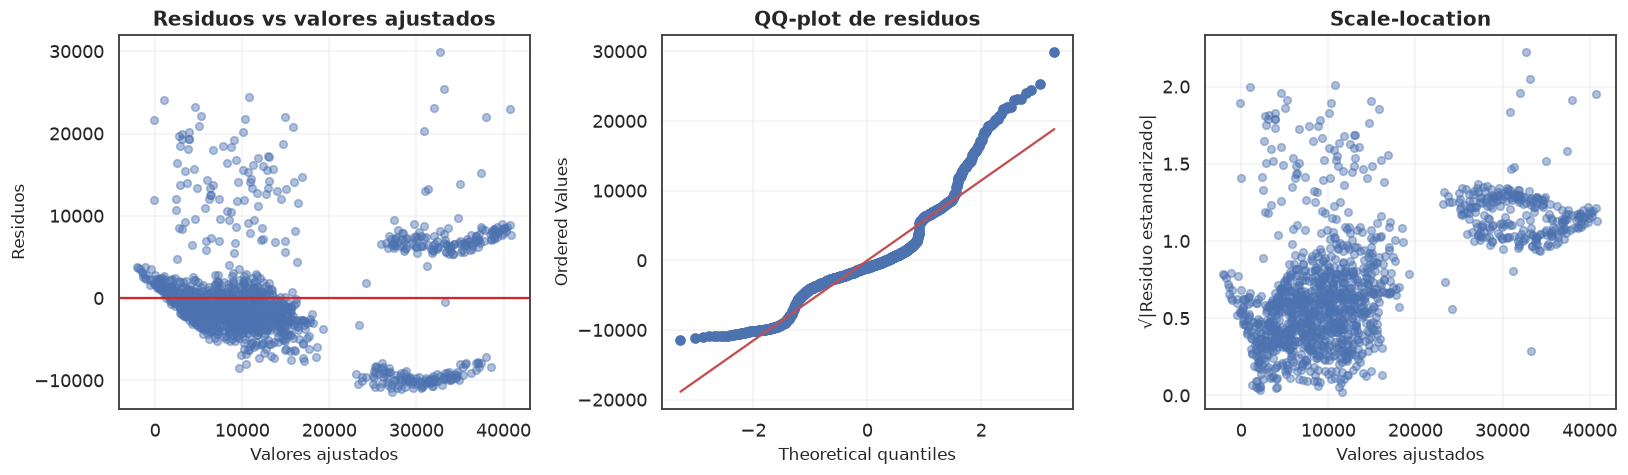

Shapiro-Wilk sobre residuos: W = 0.8834, p = 5.746e-19
Nota: con muestras grandes, pequeñas desviaciones de normalidad son esperables;
el modelo sigue siendo útil para inferencia y predicción.


In [29]:
fitted = modelo_multi.fittedvalues
resid = modelo_multi.resid
infl = modelo_multi.get_influence()
std_resid = infl.resid_studentized_internal

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Residuos vs ajustados
axes[0].scatter(fitted, resid, alpha=0.45, s=25, color="#4C72B0")
axes[0].axhline(0, color="#d62728", lw=1.5)
axes[0].set_title("Residuos vs valores ajustados", fontweight="bold")
axes[0].set_xlabel("Valores ajustados")
axes[0].set_ylabel("Residuos")
axes[0].grid(True, alpha=0.25)

# QQ-plot de residuos
stats.probplot(resid, dist="norm", plot=axes[1])
axes[1].set_title("QQ-plot de residuos", fontweight="bold")
axes[1].grid(True, alpha=0.25)

# Scale-location
axes[2].scatter(fitted, np.sqrt(np.abs(std_resid)), alpha=0.45, s=25, color="#4C72B0")
axes[2].set_title("Scale-location", fontweight="bold")
axes[2].set_xlabel("Valores ajustados")
axes[2].set_ylabel("√|Residuo estandarizado|")
axes[2].grid(True, alpha=0.25)

plt.tight_layout()
plt.show()

# Prueba de normalidad de residuos
sh_stat, sh_p = stats.shapiro(resid.sample(min(500, len(resid)), random_state=42))
print(f"Shapiro-Wilk sobre residuos: W = {sh_stat:.4f}, p = {sh_p:.4g}")
print("Nota: con muestras grandes, pequeñas desviaciones de normalidad son esperables;")
print("el modelo sigue siendo útil para inferencia y predicción.")


### 5.4 Predicción con intervalo

Se predice el costo para un perfil de ejemplo: 40 años, IMC 30, 1 hijo, fumador, región sureste.


In [30]:
nuevo = pd.DataFrame({
    "age": [40],
    "bmi": [30.0],
    "children": [1],
    "smoker": ["yes"],
    "region": ["southeast"],
})
pred = modelo_multi.get_prediction(nuevo)
resumen_pred = pred.summary_frame(alpha=0.05)
print(resumen_pred.round(2))
print(f"\nPredicción puntual: {resumen_pred['mean'].iloc[0]:,.2f} USD")
print(f"Intervalo de confianza (media):   [{resumen_pred['mean_ci_lower'].iloc[0]:,.2f}, {resumen_pred['mean_ci_upper'].iloc[0]:,.2f}]")
print(f"Intervalo de predicción (individuo): [{resumen_pred['obs_ci_lower'].iloc[0]:,.2f}, {resumen_pred['obs_ci_upper'].iloc[0]:,.2f}]")


      mean  mean_se  mean_ci_lower  mean_ci_upper  obs_ci_lower  obs_ci_upper
0  31724.0   453.54       30834.27       32613.74      19797.93      43650.07

Predicción puntual: 31,724.00 USD
Intervalo de confianza (media):   [30,834.27, 32,613.74]
Intervalo de predicción (individuo): [19,797.93, 43,650.07]


## 6. Conclusiones

**Respuesta a la pregunta principal.** El costo del seguro médico se explica principalmente por el **hábito de fumar** (sobrecosto muy grande y significativo), seguido por la **edad** y el **IMC**. El número de hijos y la región aportan poco una vez controladas las demás variables. El modelo de regresión múltiple alcanza un R² ajustado alto, lo que indica buen poder explicativo.

**Recomendaciones.**
- Las aseguradoras y programas de salud pública deberían priorizar intervenciones de **cesación tabáquica**, pues es el factor con mayor impacto en el costo.
- El **control del IMC** (prevención de obesidad) es el segundo palanca modificable más relevante.
- La **edad** no es modificable pero permite ajustar primas y planes preventivos por grupo etario.
- Las diferencias por región son pequeñas; no justifican políticas diferenciadas por zona.

**Limitaciones.**
- Datos observacionales: las asociaciones no implican causalidad (posible confusión por variables no medidas, p. ej., historial médico).
- La base es pública y puede no representar la población local; los costos están en USD y corresponden al mercado estadounidense.
- `charges` presenta distribución asimétrica con mezcla de grupos (fumadores/no fumadores), lo que afecta el ajuste de distribuciones simples.
- Tamaño muestral moderado (n ≈ 1.337) y sin información sobre variables clínicas adicionales.
- Un registro duplicado fue eliminado; no se imputaron faltantes porque no existían.
